# 国别样本可比性分析
沿用第一阶段候选国家及筛选口径。以作文为单位，保留原始错句记录数；不修改源数据。

## 1. 环境与数据读取

In [1]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/interim/errors_merged.csv').exists()), None)
if root is None:
    raise FileNotFoundError('请从项目目录运行')
output = root/'reports/exploration/sample_comparability'
output.mkdir(parents=True, exist_ok=True)
fonts = {f.name for f in font_manager.fontManager.ttflist}
font = next((f for f in ['PingFang SC','Heiti SC','Arial Unicode MS','Noto Sans CJK SC','SimHei'] if f in fonts), None)
if font: plt.rcParams['font.sans-serif'] = [font]
plt.rcParams['axes.unicode_minus'] = False
country, essay = '国籍', '作文编码'
fields = ['考试时间','作文分数','总分','证书','题目','性别']
df = pd.read_csv(root/'data/interim/errors_merged.csv', dtype={country:'string',essay:'string','考试时间':'string'})
print(df.columns.tolist())
df = df.rename(columns={'作文题目': '题目'})
assert set([country,essay,*fields]).issubset(df.columns), '请根据上方实际列名调整 fields 及后续字段引用'
candidates = pd.read_csv(root/'reports/exploration/country_distribution/candidate_countries.csv')
order = candidates[country].tolist()
print(order)
def save(table, name):
    table.to_csv(output/f'{name}.csv', encoding='utf-8-sig')
def finish(fig, name):
    fig.tight_layout(); fig.savefig(output/f'{name}.png', dpi=160, bbox_inches='tight'); plt.show(); plt.close(fig)
def heat(table, title, name, vmax=None):
    if table.empty: return
    fig, ax = plt.subplots(figsize=(max(8, min(18, .55*len(table.columns))), 5))
    im = ax.imshow(table.to_numpy(dtype=float), aspect='auto', vmin=0, vmax=vmax, cmap='Blues')
    ax.set_xticks(range(len(table.columns)), labels=table.columns, rotation=60, ha='right')
    ax.set_yticks(range(len(table.index)), labels=table.index)
    ax.set_title(title); fig.colorbar(im, ax=ax); finish(fig,name)

['record_id', '作文编码', '国籍', '性别', '考试时间', '作文题目', '口试分数', '作文分数', '听力分数', '阅读分数', '综合分数', '总分', '证书', '检索原句', 'source_file', 'source_row']
['韩国', '日本', '新加坡', '印度尼西亚', '马来西亚', '泰国', '越南', '缅甸', '澳大利亚', '美国', '英国']


## 2. 构建作文层级数据
复用第一阶段的国籍冲突排除规则。其他字段若同篇存在多个非空值，则仅将该字段设为缺失，不删除整篇。

In [2]:
work = df.copy()
for col in [country,essay,*fields]:
    work[col] = work[col].astype('string').str.strip().replace('',pd.NA)
valid = work.dropna(subset=[country,essay])
conflicts = valid.groupby(essay)[country].nunique().loc[lambda s:s>1]
sample = valid.loc[~valid[essay].isin(conflicts.index) & valid[country].isin(order)].copy()
g = sample.groupby(essay)
meta_conflicts = g[fields].nunique().gt(1)
essays = g[[country,*fields]].first()
for col in fields: essays.loc[meta_conflicts[col],col] = pd.NA
essays['错句记录数'] = g.size()
for col in ['作文分数','总分']: essays[col] = pd.to_numeric(essays[col],errors='coerce')
t = essays['考试时间'].astype('string')
valid_time = t.str.fullmatch(r'\d{4}(00|0[1-9]|1[0-2])').fillna(False)
essays['考试年份'] = pd.to_numeric(t.str[:4].where(valid_time),errors='coerce').astype('Int64')
print('作文数',len(essays),'错句记录数',essays['错句记录数'].sum())
print('元数据冲突作文数：'); display(meta_conflicts.sum())
check = essays.groupby(country).size().reindex(order,fill_value=0)
assert check.eq(candidates.set_index(country)['作文数'].reindex(order)).all(), '与第一阶段样本数不一致，请核验'
save(meta_conflicts.sum().to_frame('冲突作文数'),'metadata_conflicts')

作文数 10530 错句记录数 145564
元数据冲突作文数：


考试时间    0
作文分数    0
总分      0
证书      0
题目      0
性别      0
dtype: int64

## 3. 关键字段完整性
缺失率以各国全部纳入作文为分母，包含冲突及无法解析的值。

,考试年份,作文分数,总分,证书,题目,性别
国籍,,,,,,
韩国,0.0,0.00,0.0,0.0,0.0,0.0
日本,0.0,1.37,0.0,0.0,0.0,0.0
新加坡,0.0,0.12,0.0,0.0,0.0,0.0
印度尼西亚,0.0,0.00,0.0,0.0,0.0,0.0
马来西亚,0.0,0.00,0.0,0.0,0.0,0.0
泰国,0.0,0.00,0.0,0.0,0.0,0.0
越南,0.0,0.00,0.0,0.0,0.0,0.0
缅甸,0.0,0.00,0.0,0.0,0.0,0.0
澳大利亚,0.0,0.81,0.0,0.0,0.0,0.0


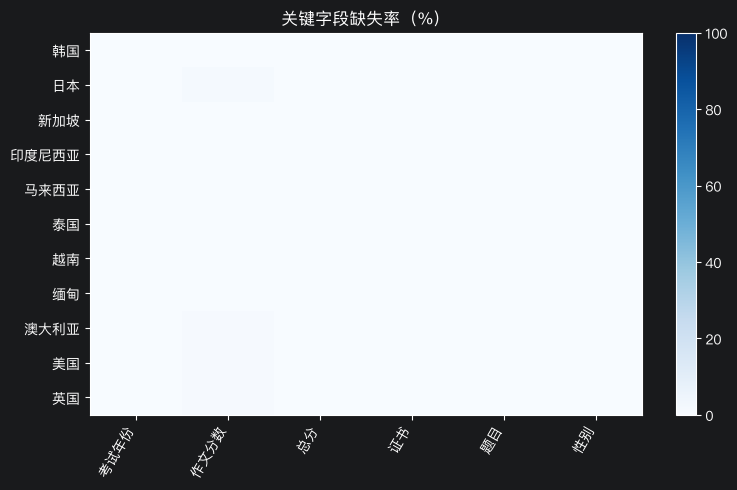

In [3]:
cols = ['考试年份','作文分数','总分','证书','题目','性别']
missing = essays[cols].isna().groupby(essays[country]).mean().reindex(order)
display((missing*100).round(2)); save(missing,'missing_rates')
heat(missing*100,'关键字段缺失率（%）','missing_heatmap',100)

## 4. 考试年份分布
月份00仍可用于年度分析。比例分母为各国年份有效作文。

考试年份,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005
国籍,,,,,,,,,,,,,,
韩国,0,41,92,158,423,56,85,76,89,516,486,1128,510,509
日本,44,55,89,130,219,46,30,37,73,636,343,494,515,500
新加坡,1,118,4,116,99,2,1,0,0,26,22,54,98,302
印度尼西亚,0,23,1,25,20,5,3,8,1,188,143,118,52,152
马来西亚,0,7,2,112,26,1,1,0,1,26,46,63,73,64
泰国,0,4,9,43,40,28,23,28,1,28,32,49,25,64
越南,0,7,3,2,6,1,35,19,1,25,9,26,31,56
缅甸,0,0,0,0,0,0,0,1,0,20,26,45,45,65
澳大利亚,1,1,1,2,23,17,9,1,8,7,12,8,5,28


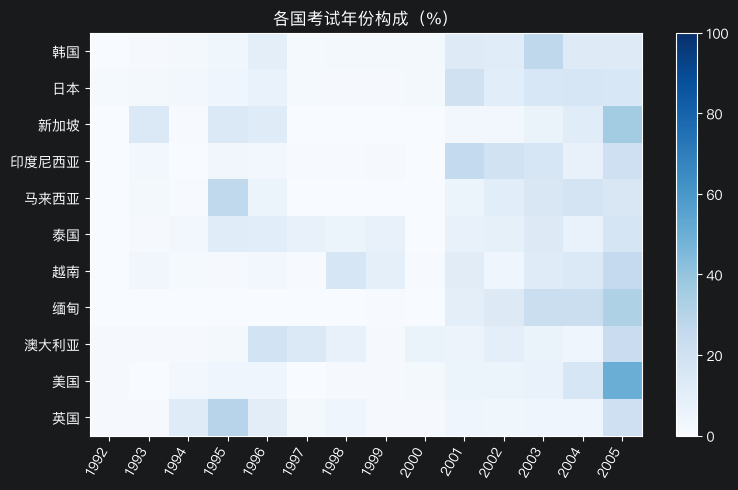

In [4]:
def distribution(col, name):
    counts = pd.crosstab(essays[country], essays[col]).reindex(order,fill_value=0)
    shares = counts.div(counts.sum(axis=1).replace(0,np.nan),axis=0)
    save(counts,name+'_counts'); save(shares,name+'_shares')
    return counts,shares
years, ys = distribution('考试年份','year')
display(years); heat(ys*100,'各国考试年份构成（%）','year_heatmap',100)

## 5. 成绩与证书等级
成绩是水平代理变量，作文成绩与偏误本身可能相关。

,count,mean,std,min,25%,50%,75%,max
国籍,,,,,,,,
韩国,4169.0,65.91,8.98,0.0,60.0,65.0,70.0,95.0
日本,3167.0,67.89,9.45,40.0,60.0,65.0,75.0,95.0
新加坡,842.0,77.1,10.26,8.0,70.0,75.0,85.0,95.0
印度尼西亚,739.0,72.49,12.18,0.0,65.0,70.0,85.0,95.0
马来西亚,422.0,80.7,11.52,0.0,75.0,85.0,90.0,95.0
泰国,374.0,70.16,12.05,40.0,61.25,70.0,80.0,95.0
越南,221.0,71.74,11.5,40.0,65.0,70.0,80.0,95.0
缅甸,202.0,74.73,10.83,40.0,65.0,75.0,85.0,95.0
澳大利亚,122.0,73.77,9.58,40.0,70.0,75.0,80.0,95.0


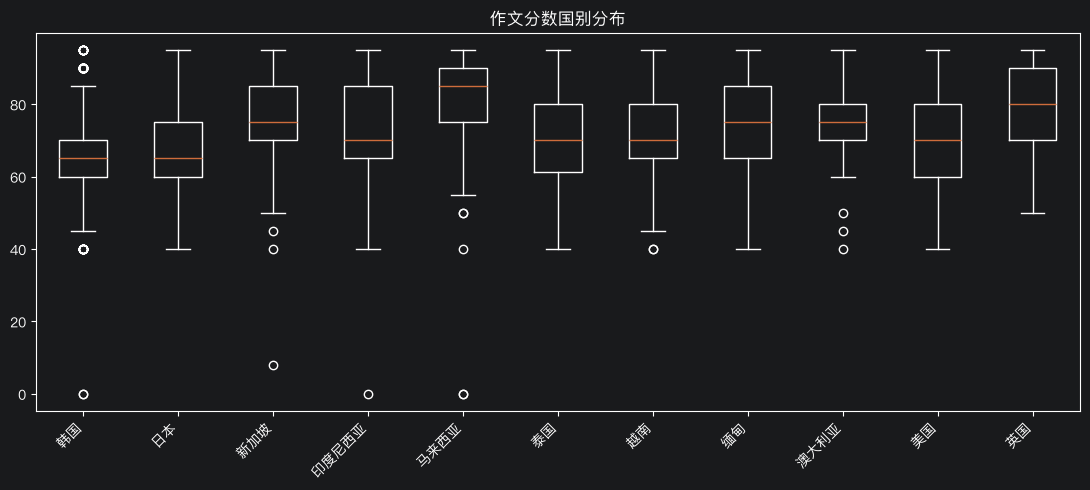

,count,mean,std,min,25%,50%,75%,max
国籍,,,,,,,,
韩国,4169.0,289.07,48.5,111.0,256.0,288.0,321.0,450.0
日本,3211.0,295.96,58.55,0.0,266.0,299.0,331.0,458.0
新加坡,843.0,363.2,46.83,0.0,335.0,369.0,395.0,460.0
印度尼西亚,739.0,310.12,53.37,131.0,275.0,310.0,349.0,453.0
马来西亚,422.0,378.27,42.94,160.0,359.25,385.0,408.0,459.0
泰国,374.0,292.95,63.85,111.0,245.0,288.0,333.75,457.0
越南,221.0,294.58,57.88,153.0,255.0,292.0,336.0,435.0
缅甸,202.0,317.57,60.35,167.0,277.25,320.5,363.0,475.0
澳大利亚,123.0,337.19,62.74,0.0,302.5,341.0,380.0,450.0


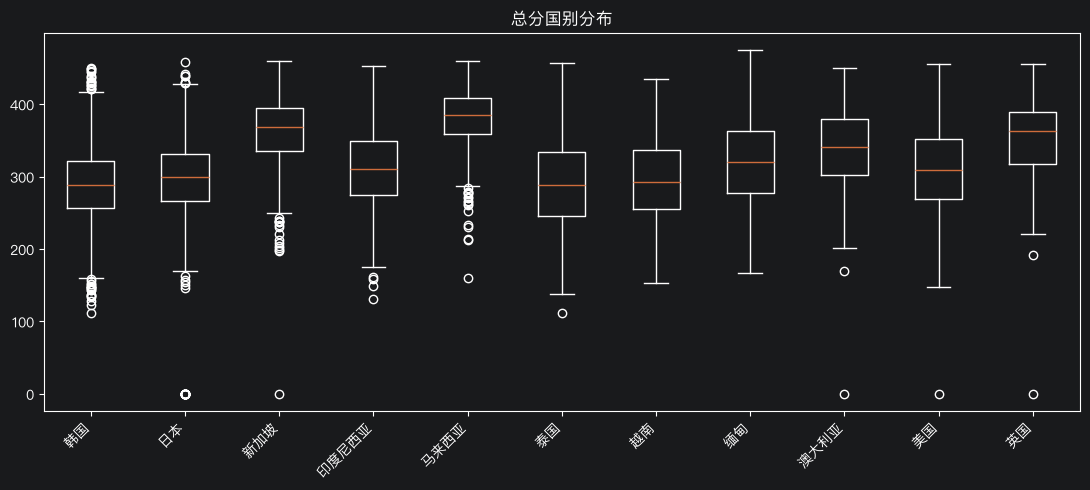

证书,A,B,C,无
国籍,,,,
韩国,19,307,1604,2239
日本,19,312,1315,1565
新加坡,66,338,321,118
印度尼西亚,10,88,278,363
马来西亚,59,218,102,43
泰国,11,41,99,223
越南,3,24,67,127
缅甸,2,38,68,94
澳大利亚,8,33,47,35


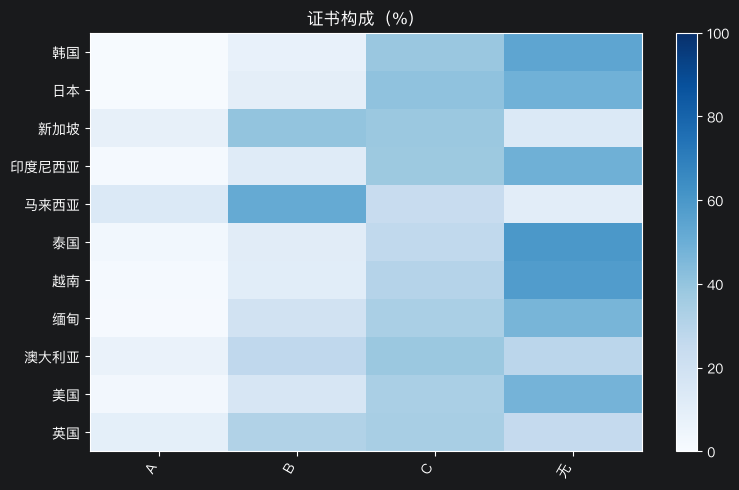

In [5]:
for col, name in [('作文分数','writing_score'),('总分','total_score')]:
    desc = essays.groupby(country)[col].describe().reindex(order)
    display(desc.round(2)); save(desc,name+'_summary')
    groups = [essays.loc[essays[country].eq(k),col].dropna().to_numpy() for k in order]
    fig,ax = plt.subplots(figsize=(11,5)); ax.boxplot(groups); ax.set_xticks(range(1,len(order)+1),order,rotation=45,ha='right'); ax.set_title(col+'国别分布'); finish(fig,name+'_boxplot')
cert, cs = distribution('证书','certificate')
display(cert); heat(cs*100,'证书构成（%）','certificate_heatmap',100)

## 6. 作文题目分布
完整表导出；图中仅展示总体最常见的15个题目，比例仍以全部有效题目为分母。

题目,绿色食品与饥饿,吸烟对个人健康和公众利益的影响,由“三个和尚没水喝”想到的……,如何解决“代沟”问题,父母是孩子的第一任老师,我看流行歌曲,一封写给父母的信,记对我影响最大的一个人,如何看待“安乐死”,一封求职信,我对男女分班的看法,我的一个假期,如何面对挫折,最理想的结交方式,学习汉语的苦与乐
国籍,,,,,,,,,,,,,,,
韩国,1128,510,246,581,9,500,514,173,118,54,0,1,77,0,85
日本,322,515,450,3,500,0,62,174,395,99,71,258,62,0,31
新加坡,7,5,95,4,8,5,0,134,3,270,141,0,3,93,1
印度尼西亚,21,34,23,121,60,89,23,29,16,24,3,10,15,2,3
马来西亚,2,60,25,6,9,3,34,62,5,71,72,4,3,37,1
泰国,7,21,32,26,17,47,11,14,15,4,29,1,31,0,43
越南,2,22,2,0,37,6,18,3,10,7,0,3,23,13,6
缅甸,0,43,20,0,1,0,0,26,0,0,0,0,1,64,0
澳大利亚,0,5,1,31,21,7,1,3,1,2,7,6,11,0,1


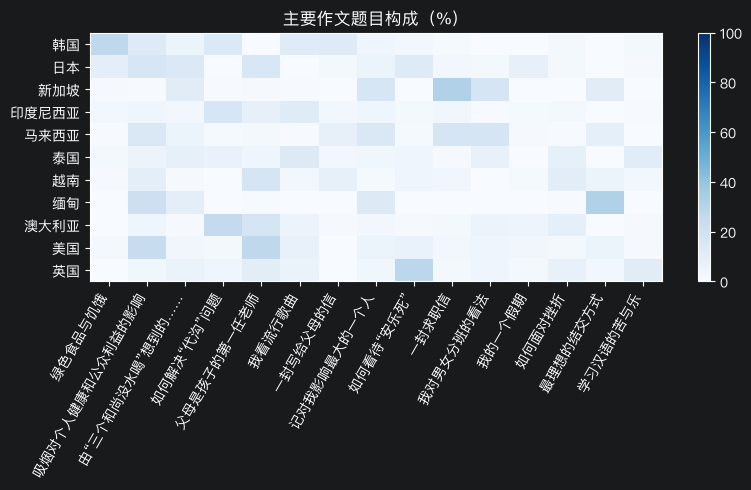

In [6]:
topics, ts = distribution('题目','topic')
top = topics.sum().nlargest(15).index
display(topics[top]); heat(ts[top]*100,'主要作文题目构成（%）','topic_heatmap',100)

## 7. 性别分布

性别,女,男
国籍,,
韩国,2558,1611
日本,1906,1305
新加坡,574,269
印度尼西亚,510,229
马来西亚,258,164
泰国,231,143
越南,146,75
缅甸,120,82
澳大利亚,74,49


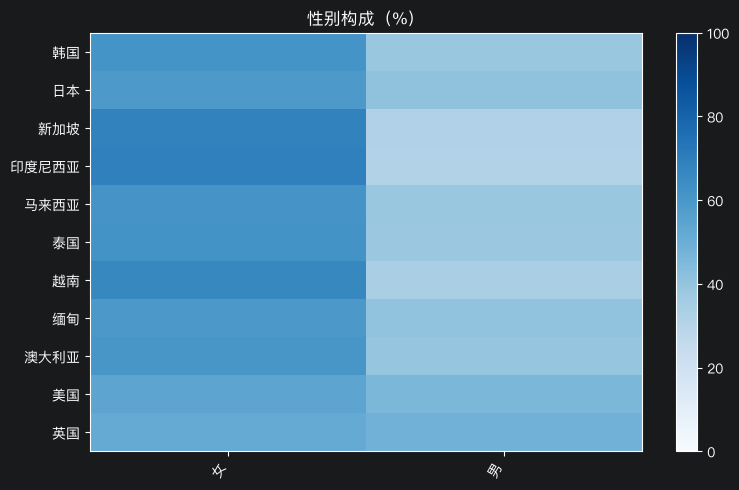

In [7]:
sex, ss = distribution('性别','gender')
display(sex); heat(ss*100,'性别构成（%）','gender_heatmap',100)

## 8. 错句记录数的分层比较
使用全体候选国家共同的作文成绩四分位切点，每个单元格同时报告样本量；少于20篇的均值不展示。

,size,mean,median,std
国籍,,,,
韩国,4169,14.31,14.0,5.98
日本,3211,14.63,14.0,4.80
新加坡,843,13.20,13.0,5.00
印度尼西亚,739,11.56,11.0,4.83
马来西亚,422,13.96,14.0,5.14
泰国,374,10.64,10.0,4.80
越南,221,11.50,11.0,5.71
缅甸,202,12.06,11.0,5.68
澳大利亚,123,13.40,14.0,4.28


作文成绩分组,"(-0.001, 60.0]","(60.0, 70.0]","(70.0, 75.0]","(75.0, 95.0]"
国籍,,,,
韩国,11.86,15.54,16.30,15.50
日本,12.77,15.03,16.10,15.95
新加坡,8.73,13.41,13.28,13.70
印度尼西亚,8.78,11.50,12.23,13.03
马来西亚,8.82,12.50,13.96,14.72
泰国,8.13,10.67,11.61,12.44
越南,9.46,10.18,13.45,13.04
缅甸,8.58,11.44,12.22,13.60
澳大利亚,NaN,13.97,13.88,13.59


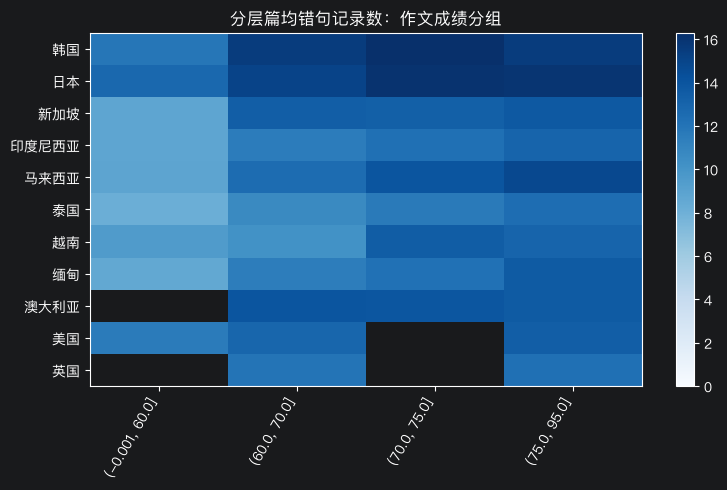

考试年份,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005
国籍,,,,,,,,,,,,,,
韩国,NaN,11.59,15.20,15.25,13.46,14.21,11.51,13.01,10.37,21.72,15.52,12.23,12.22,14.20
日本,9.55,13.87,17.17,16.58,13.49,16.70,13.93,14.49,11.77,15.99,14.46,13.71,13.96,14.95
新加坡,NaN,10.03,NaN,14.30,12.93,NaN,NaN,NaN,NaN,10.96,13.41,12.17,12.45,14.68
印度尼西亚,NaN,7.57,NaN,13.36,12.15,NaN,NaN,NaN,NaN,12.95,11.13,11.23,12.33,10.41
马来西亚,NaN,NaN,NaN,12.80,13.46,NaN,NaN,NaN,NaN,17.54,17.48,14.29,13.86,12.75
泰国,NaN,NaN,NaN,10.42,10.55,8.46,8.78,9.79,NaN,15.39,9.78,11.59,10.76,10.20
越南,NaN,NaN,NaN,NaN,NaN,NaN,7.09,NaN,NaN,16.12,NaN,10.81,12.55,12.23
缅甸,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.45,13.35,10.42,13.96,11.42
澳大利亚,NaN,NaN,NaN,NaN,11.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.96


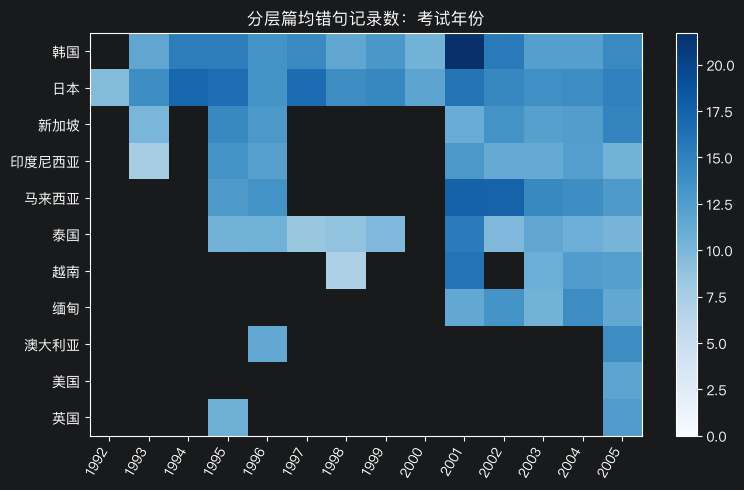

证书,A,B,C,无
国籍,,,,
韩国,NaN,14.57,14.92,13.85
日本,NaN,14.97,14.99,14.26
新加坡,13.67,13.79,13.36,10.79
印度尼西亚,NaN,12.18,12.24,10.87
马来西亚,14.59,14.71,13.17,11.21
泰国,NaN,11.71,11.76,9.80
越南,NaN,13.25,13.75,9.87
缅甸,NaN,13.82,11.75,11.57
澳大利亚,NaN,12.52,13.81,13.11


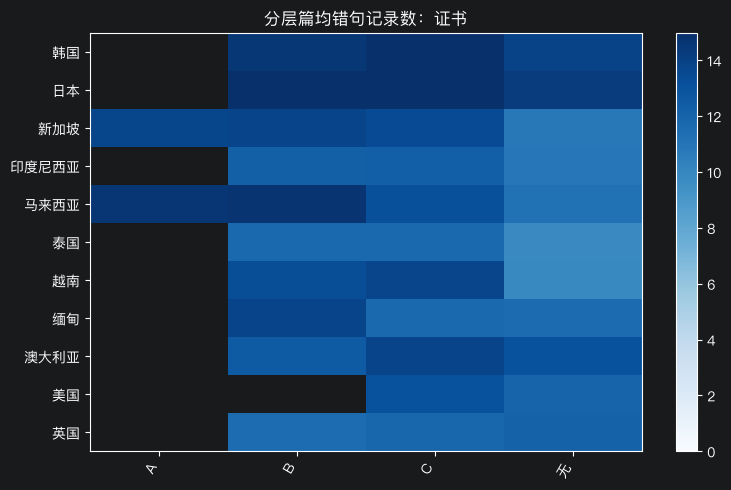

题目,绿色食品与饥饿,吸烟对个人健康和公众利益的影响,由“三个和尚没水喝”想到的……,如何解决“代沟”问题,父母是孩子的第一任老师,我看流行歌曲,一封写给父母的信,记对我影响最大的一个人,如何看待“安乐死”,一封求职信,我对男女分班的看法,我的一个假期,如何面对挫折,最理想的结交方式,学习汉语的苦与乐
国籍,,,,,,,,,,,,,,,
韩国,12.23,12.22,13.13,15.42,NaN,14.16,21.76,15.88,13.03,12.22,NaN,NaN,13.00,NaN,11.51
日本,12.89,13.96,14.13,NaN,14.95,NaN,20.37,16.95,14.41,11.95,15.89,16.41,15.44,NaN,14.23
新加坡,NaN,NaN,12.89,NaN,NaN,NaN,NaN,14.25,NaN,12.43,15.01,NaN,NaN,12.41,NaN
印度尼西亚,11.33,12.06,13.04,10.45,12.43,9.07,18.74,13.66,NaN,7.38,NaN,NaN,NaN,NaN,NaN
马来西亚,NaN,14.33,13.40,NaN,NaN,NaN,17.85,14.74,NaN,10.80,14.19,NaN,NaN,11.97,NaN
泰国,NaN,10.19,10.56,8.88,NaN,9.32,NaN,NaN,NaN,NaN,11.86,NaN,10.39,NaN,10.65
越南,NaN,13.18,NaN,NaN,12.59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.70,NaN,NaN
缅甸,NaN,14.21,11.45,NaN,NaN,NaN,NaN,13.35,NaN,NaN,NaN,NaN,NaN,11.56,NaN
澳大利亚,NaN,NaN,NaN,12.74,13.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


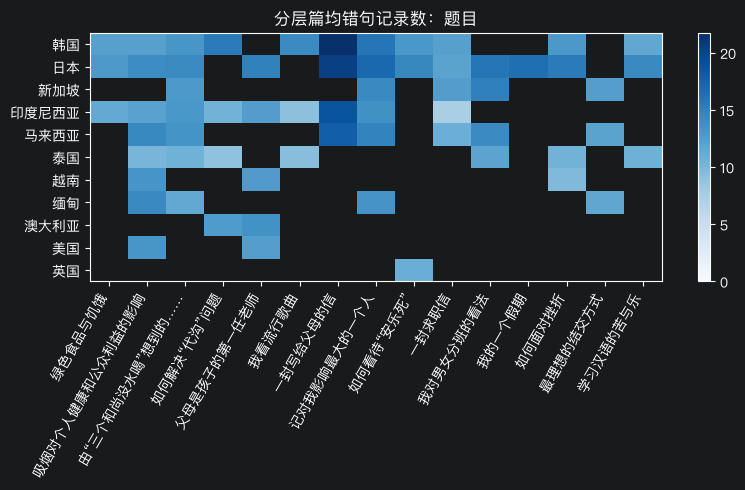

In [8]:
MIN_CELL = 20
base = essays.groupby(country)['错句记录数'].agg(['size','mean','median','std']).reindex(order)
display(base.round(2)); save(base,'error_summary')
essays['作文成绩分组'] = pd.qcut(essays['作文分数'],4,duplicates='drop')
for col,name in [('作文成绩分组','score'),('考试年份','year'),('证书','certificate'),('题目','topic')]:
    agg = essays.groupby([country,col],observed=True)['错句记录数'].agg(作文数='size',篇均错句记录数='mean')
    save(agg,'error_by_'+name)
    means = agg['篇均错句记录数'].where(agg['作文数']>=MIN_CELL).unstack().reindex(order)
    if col=='题目': means = means.reindex(columns=top)
    display(means.round(2)); heat(means,'分层篇均错句记录数：'+col,'error_by_'+name)

## 9. 两两可比性评估
共同支持定义：两个国家在同一分层取值下各至少有10篇作文。分别计算年份、题目及年份×题目的共同支持覆盖率（分母为各国全部作文，缺失不计入覆盖）。

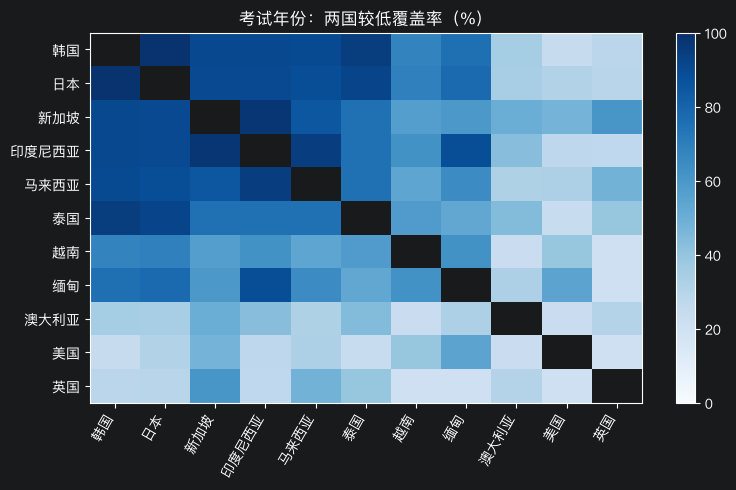

,维度,国家A,国家B,共同分层数,A覆盖作文数,B覆盖作文数,A覆盖率,B覆盖率
0,考试年份,韩国,日本,13,4169,3167,1.000,0.986
19,考试年份,新加坡,印度尼西亚,8,835,721,0.991,0.976
34,考试年份,马来西亚,泰国,7,410,281,0.972,0.751
4,考试年份,韩国,泰国,10,3947,360,0.947,0.963
27,考试年份,印度尼西亚,马来西亚,7,698,410,0.945,0.972
28,考试年份,印度尼西亚,泰国,7,698,281,0.945,0.751
13,考试年份,日本,泰国,10,2950,360,0.919,0.963
1,考试年份,韩国,新加坡,8,3771,835,0.905,0.991
2,考试年份,韩国,印度尼西亚,8,3771,721,0.905,0.976
10,考试年份,日本,新加坡,8,2892,835,0.901,0.991


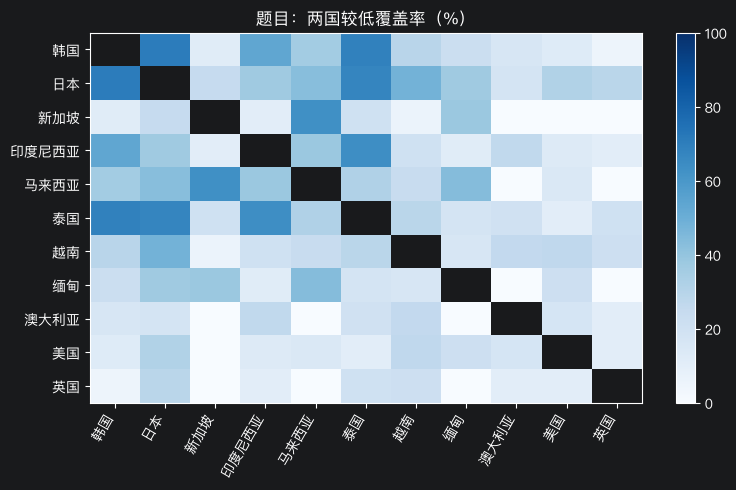

,维度,国家A,国家B,共同分层数,A覆盖作文数,B覆盖作文数,A覆盖率,B覆盖率
57,题目,韩国,印度尼西亚,10,3901,395,0.936,0.535
66,题目,日本,印度尼西亚,11,2887,272,0.899,0.368
75,题目,新加坡,马来西亚,5,733,267,0.870,0.633
83,题目,印度尼西亚,泰国,11,575,239,0.778,0.639
55,题目,韩国,日本,12,3078,2267,0.738,0.706
68,题目,日本,泰国,11,2352,251,0.732,0.671
59,题目,韩国,泰国,10,2856,265,0.685,0.709
89,题目,马来西亚,泰国,6,272,119,0.645,0.318
74,题目,新加坡,印度尼西亚,3,499,76,0.592,0.103
69,题目,日本,越南,5,1534,110,0.478,0.498


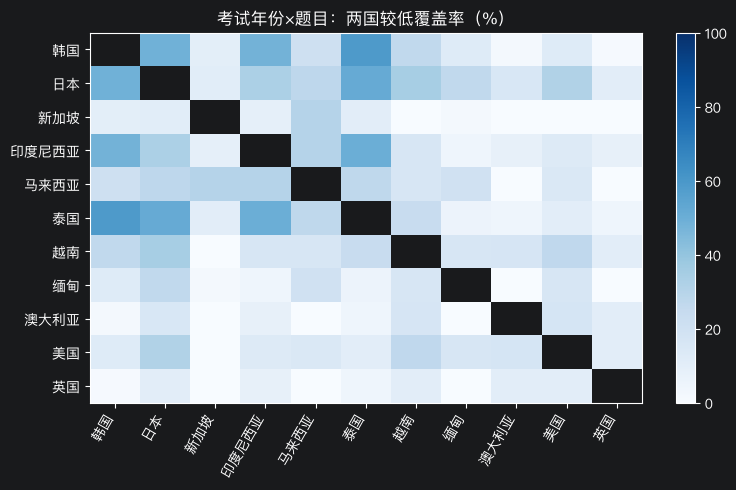

,维度,国家A,国家B,共同分层数,A覆盖作文数,B覆盖作文数,A覆盖率,B覆盖率
112,考试年份×题目,韩国,印度尼西亚,8,3544,353,0.850,0.478
121,考试年份×题目,日本,印度尼西亚,10,2398,243,0.747,0.329
110,考试年份×题目,韩国,日本,13,3022,1565,0.725,0.487
138,考试年份×题目,印度尼西亚,泰国,9,534,186,0.723,0.497
130,考试年份×题目,新加坡,马来西亚,5,591,128,0.701,0.303
114,考试年份×题目,韩国,泰国,10,2669,220,0.640,0.588
144,考试年份×题目,马来西亚,泰国,5,224,101,0.531,0.270
123,考试年份×题目,日本,泰国,11,1650,206,0.514,0.551
129,考试年份×题目,新加坡,印度尼西亚,3,327,65,0.388,0.088
124,考试年份×题目,日本,越南,4,1114,96,0.347,0.434


In [9]:
MIN_SHARED = 10
rows=[]
for dims in [['考试年份'],['题目'],['考试年份','题目']]:
    tab = essays.groupby([country,*dims],observed=True).size().unstack(country,fill_value=0).reindex(columns=order,fill_value=0)
    for a,b in combinations(order,2):
        mask = (tab[a]>=MIN_SHARED)&(tab[b]>=MIN_SHARED)
        na,nb = int(tab.loc[mask,a].sum()),int(tab.loc[mask,b].sum())
        rows.append({'维度':'×'.join(dims),'国家A':a,'国家B':b,'共同分层数':int(mask.sum()),'A覆盖作文数':na,'B覆盖作文数':nb,'A覆盖率':na/check[a],'B覆盖率':nb/check[b]})
pairs = pd.DataFrame(rows); save(pairs,'pairwise_common_support')
for dim, part in pairs.groupby('维度',sort=False):
    matrix = pd.DataFrame(np.nan,index=order,columns=order)
    for _,r in part.iterrows():
        matrix.loc[r['国家A'],r['国家B']] = matrix.loc[r['国家B'],r['国家A']] = min(r['A覆盖率'],r['B覆盖率'])*100
    heat(matrix,dim+'：两国较低覆盖率（%）','common_'+str(len(dim))+'_'+str(list(pairs['维度'].unique()).index(dim)),100)
    display(part.sort_values(['A覆盖率','B覆盖率'],ascending=False).head(15).round(3))

## 10. 结果与阶段性结论
本阶段对11个候选国家的10,530篇作文及145,564条错句记录进行了样本可比性分析。各国元数据完整性总体较好，未发现作文内部字段冲突，但考试年份、语言水平、作文题目及性别构成存在不同程度的差异。

篇均错句记录数的国别差异在不同条件下呈现保持、缩小、扩大或反转等现象，说明直接进行国别汇总比较可能受到样本结构的影响。此外，部分国家高分组的篇均错句记录数高于低分组，值得结合作文篇幅、语言复杂度及偏误类型进一步探索。

国别两两共同支持分析表明，韩国、日本、泰国及印度尼西亚等国家之间具备一定的同年同题比较基础，但不同国家组合的有效样本规模及覆盖率存在明显差异。

总体而言，现有HSK语料具备开展限定条件下跨国别偏误比较的可行性，但尚不足以支持具有广泛代表性的国别差异解释。

In [10]:
summary = pd.concat([check.rename('作文数'),base['mean'].rename('篇均错句记录数'),missing.add_suffix('_缺失率')],axis=1)
save(summary,'comparability_summary'); display(summary.round(3))

,作文数,篇均错句记录数,考试年份_缺失率,作文分数_缺失率,总分_缺失率,证书_缺失率,题目_缺失率,性别_缺失率
国籍,,,,,,,,
韩国,4169,14.313,0.0,0.000,0.0,0.0,0.0,0.0
日本,3211,14.627,0.0,0.014,0.0,0.0,0.0,0.0
新加坡,843,13.198,0.0,0.001,0.0,0.0,0.0,0.0
印度尼西亚,739,11.563,0.0,0.000,0.0,0.0,0.0,0.0
马来西亚,422,13.962,0.0,0.000,0.0,0.0,0.0,0.0
泰国,374,10.639,0.0,0.000,0.0,0.0,0.0,0.0
越南,221,11.498,0.0,0.000,0.0,0.0,0.0,0.0
缅甸,202,12.059,0.0,0.000,0.0,0.0,0.0,0.0
澳大利亚,123,13.398,0.0,0.008,0.0,0.0,0.0,0.0
